# Library

In [422]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data load

In [423]:
df=  pd.read_csv('housing.csv')
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [424]:
 df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [425]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [426]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [427]:
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

In [428]:
df.columns.tolist()

['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'median_house_value',
 'ocean_proximity']

# check Null value

In [429]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [430]:
df = df.dropna()

# Duplicated value

In [431]:
print(df.duplicated().sum())

0


# outline check

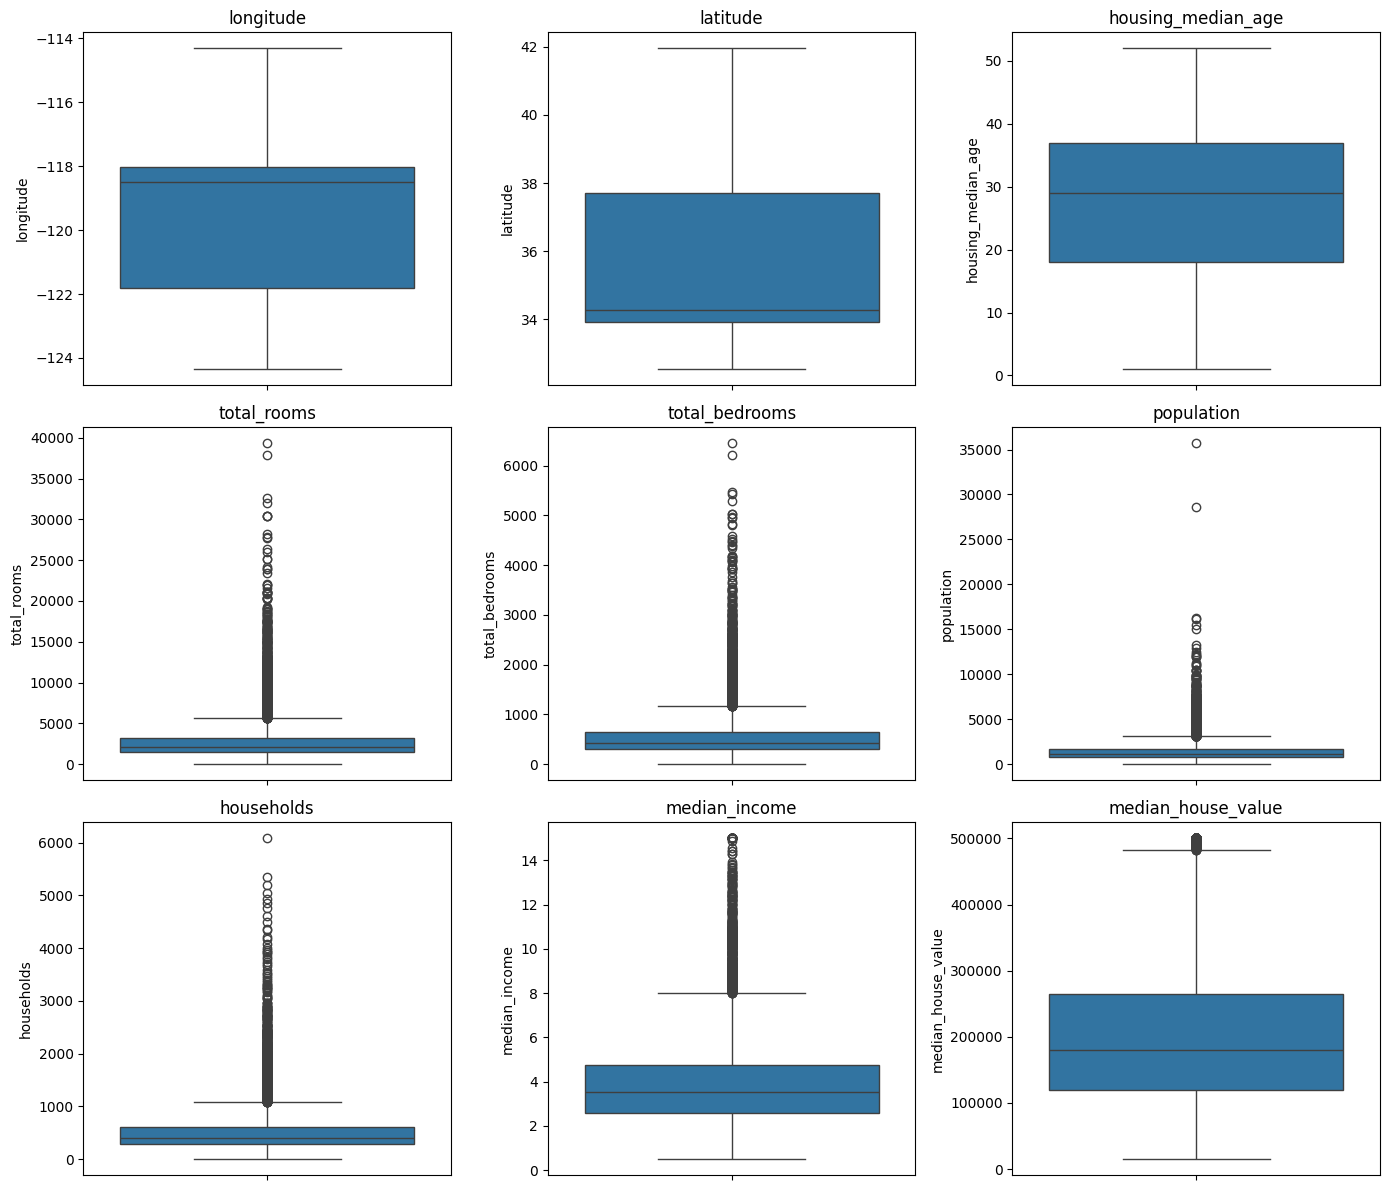

In [432]:
cols = [
    'longitude', 'latitude', 'housing_median_age',
    'total_rooms', 'total_bedrooms', 'population',
    'households', 'median_income', 'median_house_value'
]

plt.figure(figsize=(14, 12))

for i, col in enumerate(cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [433]:

cols = [
    'total_rooms', 'total_bedrooms', 'population',
    'households', 'median_income', 'median_house_value'
]


print("Rows before:", len(df))


for col in cols:
    Q1 = df[col].quantile(0.10)
    Q3 = df[col].quantile(0.90)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("Rows after:", len(df))
print("Outliers removed:", " ",)
print("Remaining outliers check complete.")

Rows before: 20433
Rows after: 19937
Outliers removed:  
Remaining outliers check complete.


# Data Encoding

In [434]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19937 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           19937 non-null  float64
 1   latitude            19937 non-null  float64
 2   housing_median_age  19937 non-null  float64
 3   total_rooms         19937 non-null  float64
 4   total_bedrooms      19937 non-null  float64
 5   population          19937 non-null  float64
 6   households          19937 non-null  float64
 7   median_income       19937 non-null  float64
 8   median_house_value  19937 non-null  float64
 9   ocean_proximity     19937 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


In [435]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["ocean_proximity"] = le.fit_transform(df["ocean_proximity"])

print(df.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value  ocean_proximity  
0       322.0       126.0         8.3252            452600.0                3  
1      2401.0      1138.0         8.3014            358500.0                3  
2       496.0       177.0         7.2574            352100.0                3  
3       558.0       219.0         5.6431            341300.0                3  
4       565.0       259.0         3.8462            342200.0                3  


# Scaling data

In [436]:
df.columns.tolist()

['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'median_house_value',
 'ocean_proximity']

In [437]:
# library 
from sklearn.preprocessing import MinMaxScaler


In [438]:
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity         int64
dtype: object

In [439]:


# Scale numerical columns
cols = ['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'median_house_value',]

scaler = MinMaxScaler()
df[cols] = scaler.fit_transform(df[cols])

print(df.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0   0.211155  0.567481            0.784314     0.085977        0.063659   
1   0.212151  0.565356            0.392157     0.694967        0.553383   
2   0.210159  0.564293            1.000000     0.143459        0.094236   
3   0.209163  0.564293            1.000000     0.124559        0.116792   
4   0.209163  0.564293            1.000000     0.159127        0.139348   

   population  households  median_income  median_house_value  ocean_proximity  
0    0.060474    0.068812       0.652103            0.902266                3  
1    0.454597    0.630411       0.650120            0.708247                3  
2    0.093460    0.097114       0.563120            0.695051                3  
3    0.105213    0.120422       0.428596            0.672783                3  
4    0.106540    0.142619       0.278856            0.674638                3  


# train_test_split

In [440]:
from sklearn.model_selection import train_test_split 
import pandas as pd 

# Features and target
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

print("Training Data Shape:", X_train.shape, y_train.shape) 
print("Testing Data Shape:", X_test.shape, y_test.shape)

Training Data Shape: (9968, 9) (9968,)
Testing Data Shape: (9969, 9) (9969,)


# correlation matrix


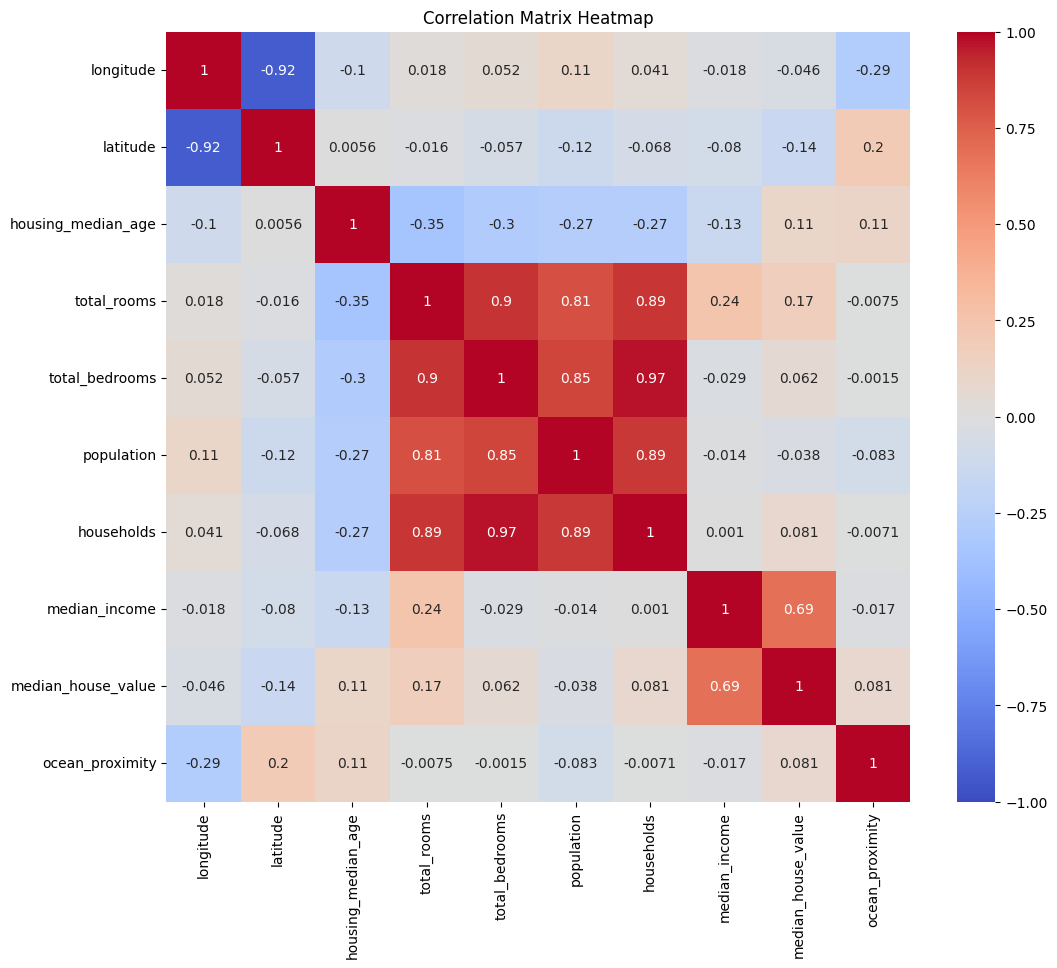

In [441]:
# Calculate correlation matrix
corr_matrix = df.corr()

# Create a heatmap
plt.figure(figsize=(12, 10)) 
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Correlation Matrix Heatmap')
plt.show()

# 1.LinearRegression Model

In [442]:
# library
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error


In [443]:
# Making and fitting the model
regressor = LinearRegression()
regressor.fit(X_train,y_train)

 # Predicting and testing the model
y_pred = regressor.predict(X_test)



In [444]:
 # Checking the model using metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test,y_pred)
print("Model Evaluation")
print("RMSE:", rmse)
print("R2 Score:", r2)
print("R2 Percentage:", r2 * 100, "%")

Model Evaluation
RMSE: 0.13894669265350557
R2 Score: 0.6476528484463209
R2 Percentage: 64.76528484463209 %


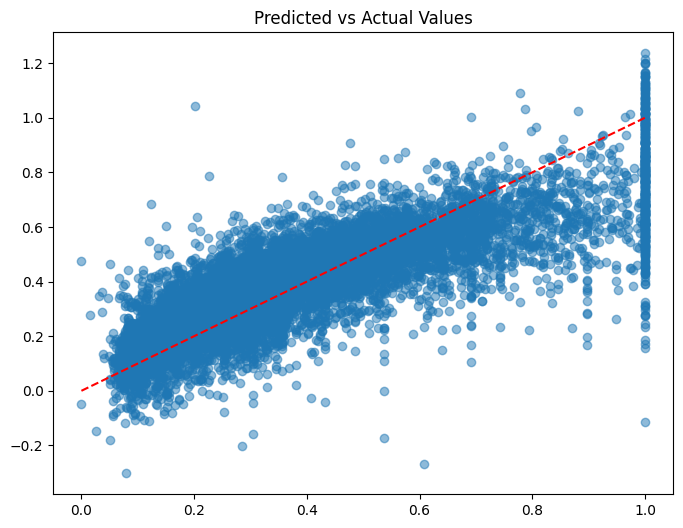

In [445]:
 # Plotting Actual vs Predicted Graph
 plt.figure(figsize=(8,6))
 plt.scatter(y_test, y_pred, alpha=0.5)
 plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', ls = '--')
 
 plt.title("Predicted vs Actual Values")
 plt.show()

# 2.Descision Tree Regressor

In [446]:
# Libraries
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error

In [447]:
model =DecisionTreeRegressor(random_state = 42, max_depth= 10, min_samples_split =0.06)
model.fit(X_train,y_train)

y_pred = model.predict(X_test)
y_pred

array([0.38963181, 0.17705486, 0.37068353, ..., 0.35052239, 0.20111359,
       0.62856572], shape=(9969,))

In [448]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("RMSE:", rmse)
print("R2 Score:", r2)
print("R2 Percentage:", r2 * 100, "%")

Model Evaluation
RMSE: 0.14201290882616874
R2 Score: 0.6319303708100139
R2 Percentage: 63.19303708100139 %


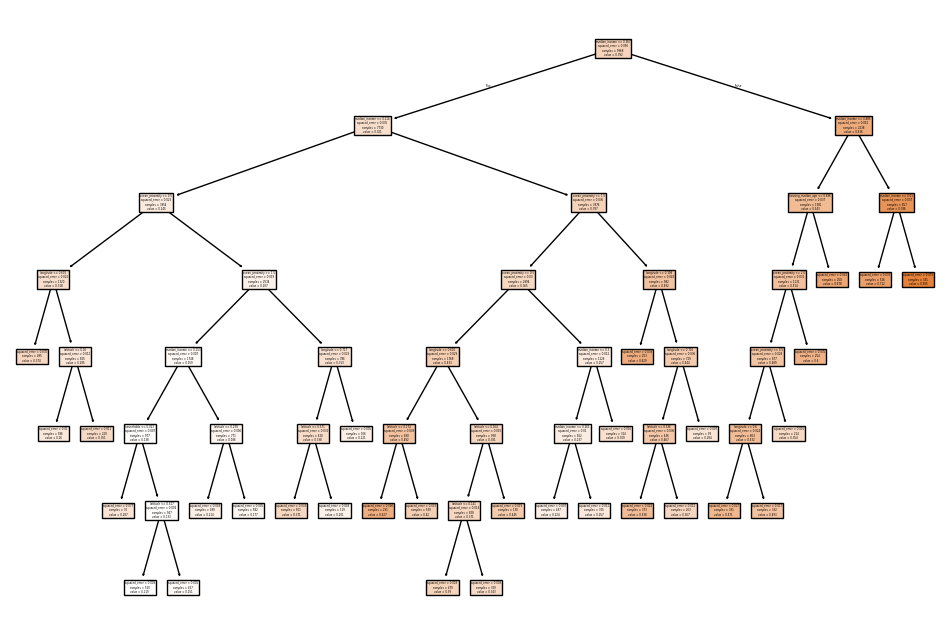

In [449]:
 # Visualizing With tree plot
plt.figure(figsize = (12,8))
plot_tree(model,feature_names = X_train.columns,filled = True)
plt.show()

# 4.Random Forest Regressor


In [450]:
from sklearn.ensemble import RandomForestRegressor

rf= RandomForestRegressor(n_estimators = 100,random_state=42)
model=rf.fit(X_train,y_train)


y_pred = model.predict(X_test)
y_pred

array([0.35220061, 0.22946297, 0.15592513, ..., 0.41867873, 0.29065447,
       0.55944512], shape=(9969,))

In [451]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("RMSE:", rmse)
print("R2 Score:", r2)
print("R2 Percentage:", r2 * 100, "%")

Model Evaluation
RMSE: 0.10458785270773659
R2 Score: 0.8003649326432063
R2 Percentage: 80.03649326432063 %


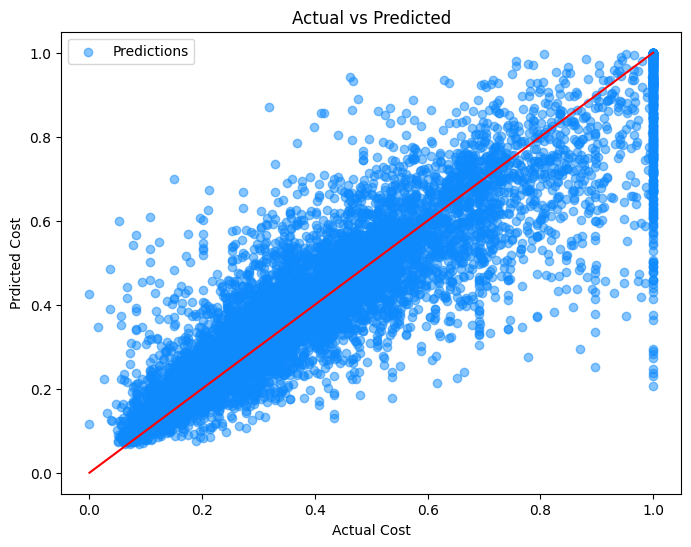

In [452]:
plt.figure(figsize = (8, 6))
c = '#0f8afc'
 
plt.scatter(y_test, y_pred, alpha = 0.5, color = c, label = 'Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], c = 'r') 
plt.xlabel('Actual Cost')
plt.ylabel('Prdicted Cost')
plt.title('Actual vs Predicted')
plt.legend()

Text(0.5, 1.0, 'Residual Plot')

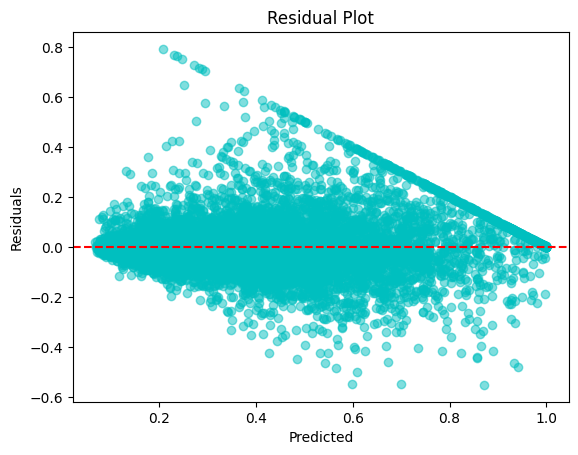

In [453]:
# Visualizing the model metrics
 # Residual Plot

residuals = y_test - y_pred
plt.scatter(y_pred, residuals, color ='c', alpha = 0.5)
plt.axhline(0, ls = '--', color = 'r')
plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residual Plot')

# Compare models with bar chart

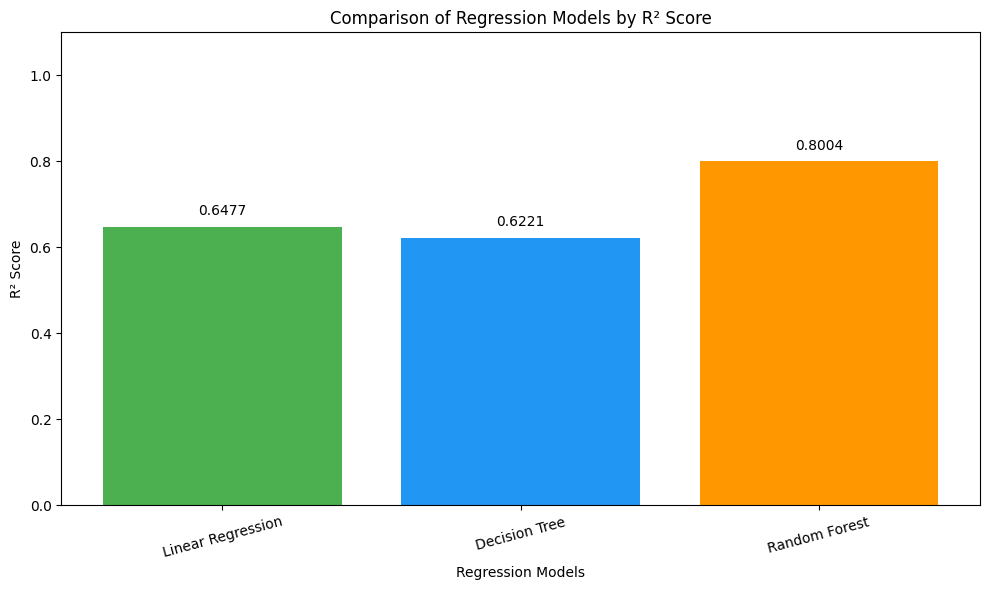

In [454]:


# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),

}

# Train models and compute R² Scores
r2_scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    r2_scores[name] = r2_score(y_test, y_pred)



# Plot bar chart with R² scores on top
plt.figure(figsize=(10, 6))
bars = plt.bar(r2_scores.keys(), r2_scores.values(), color=['#4CAF50', '#2196F3', '#FF9800', '#F44336', '#9C27B0'])
plt.xlabel('Regression Models')
plt.ylabel('R² Score')
plt.title('Comparison of Regression Models by R² Score')
plt.ylim(0, 1.1)  # Extend y-axis slightly to accommodate text labels
plt.xticks(rotation=15)

# Add R² scores on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()